# Module 08 — Distributions and Limit Theorems

This notebook is the runnable companion to the concept guide: read [README.md](README.md) first, or keep
it open alongside. Each section mirrors a numbered section of the guide. We draw a gallery of the named
distributions, verify every mean and variance formula by simulation, watch the Binomial turn into the
Poisson, check memorylessness numerically, test the 68–95–99.7 rule with a Q–Q plot, grow a Beta posterior,
build the Gamma, Chi-square and Student-t from their ingredients, confirm an MGF identity, watch the law of
large numbers work (and fail for the Cauchy), see the central limit theorem emerge at different speeds, and
finish with a Monte Carlo integral whose error bars shrink like $1/\sqrt{n}$.

Everything is computed in plain NumPy first; `scipy.stats` appears afterwards to confirm the hand computation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb, exp, factorial, log, sqrt, pi
from scipy import stats
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)

## 1. A distribution is a modelling assumption — the gallery

Each named distribution is a *story* about how one data point is generated, plus a few parameters. The
first gallery shows discrete PMFs, the second continuous PDFs, each with its parameters varied. Watch how a
single parameter moves the mass around, and keep the stories in mind: Binomial = successes in $n$ trials,
Geometric = trials until the first success, Poisson = rare events in a window, Exponential = waiting time at
constant rate, Normal = sum of many small effects, Gamma = waiting time for several events, Beta = a
distribution over a probability.

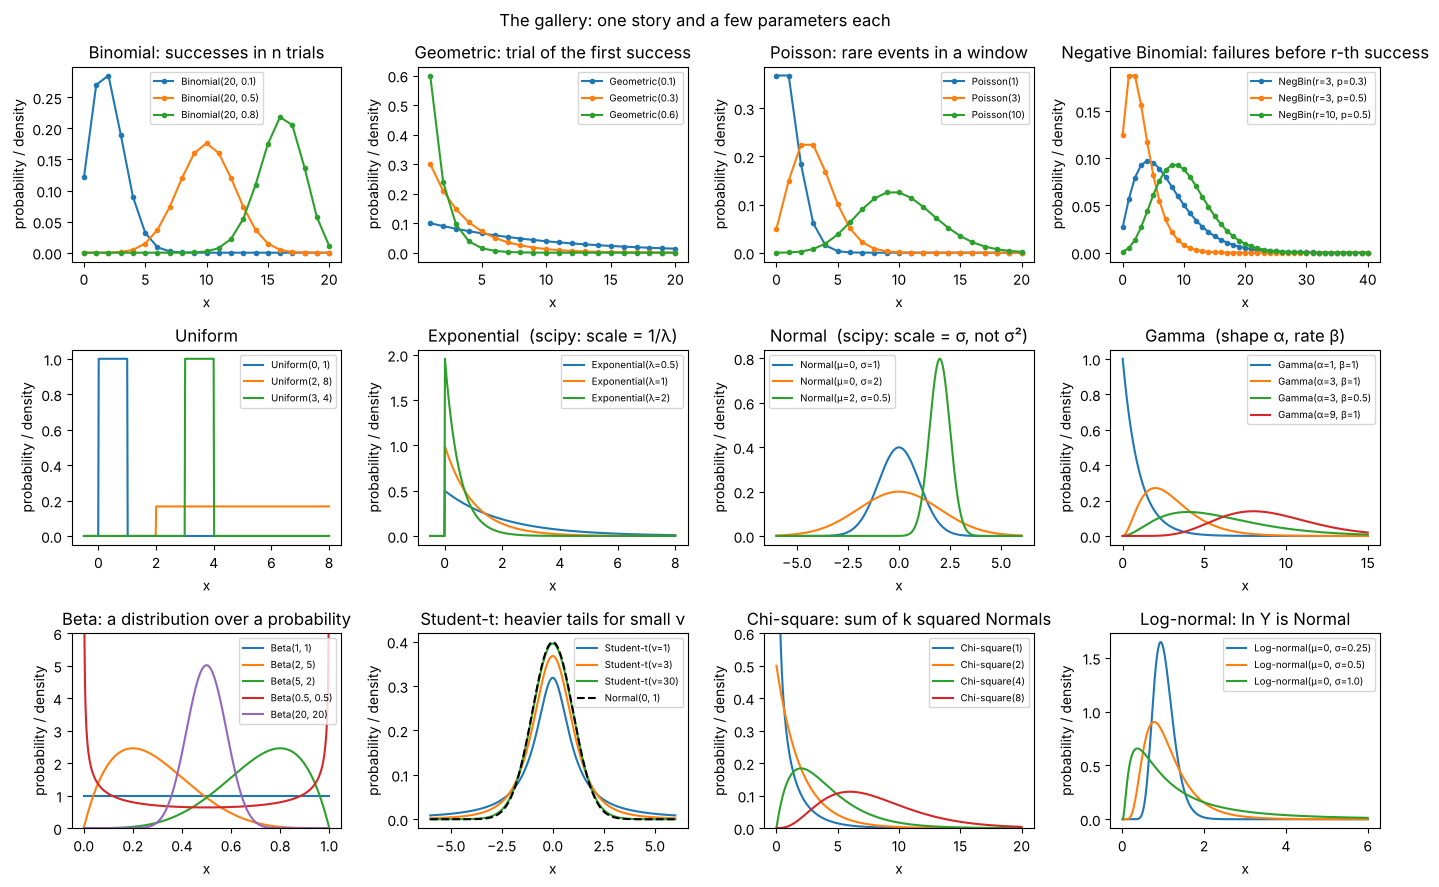

In [2]:
fig, axes = plt.subplots(3, 4, figsize=(14, 9))

k = np.arange(0, 21)
for n, p in [(20, 0.1), (20, 0.5), (20, 0.8)]:
    axes[0, 0].plot(k, stats.binom.pmf(k, n, p), "o-", ms=3, label=f"Binomial({n}, {p})")
axes[0, 0].set_title("Binomial: successes in n trials")

k = np.arange(1, 21)
for p in (0.1, 0.3, 0.6):
    axes[0, 1].plot(k, stats.geom.pmf(k, p), "o-", ms=3, label=f"Geometric({p})")
axes[0, 1].set_title("Geometric: trial of the first success")

k = np.arange(0, 21)
for lam in (1, 3, 10):
    axes[0, 2].plot(k, stats.poisson.pmf(k, lam), "o-", ms=3, label=f"Poisson({lam})")
axes[0, 2].set_title("Poisson: rare events in a window")

k = np.arange(0, 41)
for r, p in [(3, 0.3), (3, 0.5), (10, 0.5)]:
    axes[0, 3].plot(k, stats.nbinom.pmf(k, r, p), "o-", ms=3, label=f"NegBin(r={r}, p={p})")
axes[0, 3].set_title("Negative Binomial: failures before r-th success")

x = np.linspace(-0.5, 8, 500)
for a, b in [(0, 1), (2, 8), (3, 4)]:
    axes[1, 0].plot(x, stats.uniform.pdf(x, loc=a, scale=b - a), label=f"Uniform({a}, {b})")
axes[1, 0].set_title("Uniform")

for lam in (0.5, 1, 2):
    axes[1, 1].plot(x, stats.expon.pdf(x, scale=1 / lam), label=f"Exponential(λ={lam})")
axes[1, 1].set_title("Exponential  (scipy: scale = 1/λ)")

xn = np.linspace(-6, 6, 500)
for mu, sd in [(0, 1), (0, 2), (2, 0.5)]:
    axes[1, 2].plot(xn, stats.norm.pdf(xn, mu, sd), label=f"Normal(μ={mu}, σ={sd})")
axes[1, 2].set_title("Normal  (scipy: scale = σ, not σ²)")

xg = np.linspace(0, 15, 500)
for a, beta in [(1, 1), (3, 1), (3, 0.5), (9, 1)]:
    axes[1, 3].plot(xg, stats.gamma.pdf(xg, a=a, scale=1 / beta), label=f"Gamma(α={a}, β={beta})")
axes[1, 3].set_title("Gamma  (shape α, rate β)")

xb = np.linspace(0.001, 0.999, 500)
for a, b in [(1, 1), (2, 5), (5, 2), (0.5, 0.5), (20, 20)]:
    axes[2, 0].plot(xb, stats.beta.pdf(xb, a, b), label=f"Beta({a}, {b})")
axes[2, 0].set_ylim(0, 6); axes[2, 0].set_title("Beta: a distribution over a probability")

for df in (1, 3, 30):
    axes[2, 1].plot(xn, stats.t.pdf(xn, df), label=f"Student-t(ν={df})")
axes[2, 1].plot(xn, stats.norm.pdf(xn), "k--", label="Normal(0, 1)")
axes[2, 1].set_title("Student-t: heavier tails for small ν")

xc = np.linspace(0, 20, 500)
for df in (1, 2, 4, 8):
    axes[2, 2].plot(xc, stats.chi2.pdf(xc, df), label=f"Chi-square({df})")
axes[2, 2].set_ylim(0, 0.6); axes[2, 2].set_title("Chi-square: sum of k squared Normals")

xl = np.linspace(0.01, 6, 500)
for s in (0.25, 0.5, 1.0):
    axes[2, 3].plot(xl, stats.lognorm.pdf(xl, s=s, scale=1.0), label=f"Log-normal(μ=0, σ={s})")
axes[2, 3].set_title("Log-normal: ln Y is Normal")

for ax in axes.ravel():
    ax.legend(fontsize=7); ax.set_xlabel("x"); ax.set_ylabel("probability / density")
fig.suptitle("The gallery: one story and a few parameters each")
plt.tight_layout(); plt.show()

Two conventions to burn in: `scipy.stats` continuous families take `loc` and `scale`, so the Exponential
with rate $\lambda$ is `expon(scale=1/lam)`, the Normal with standard deviation $\sigma$ is
`norm(loc=mu, scale=sigma)` and the Gamma with rate $\beta$ is `gamma(a=alpha, scale=1/beta)`. The next
cell checks each object's `.mean()` and `.var()` against the formulas in the guide's cheat sheet — the
quickest way to catch a parametrisation mistake before it poisons everything downstream.

In [3]:
rows = [
    ("Binomial(20, 0.1)",     stats.binom(20, 0.1),              20 * 0.1,        20 * 0.1 * 0.9),
    ("Geometric(0.1)",        stats.geom(0.1),                    1 / 0.1,         0.9 / 0.01),
    ("NegBin(r=3, p=0.1)",    stats.nbinom(3, 0.1),               3 * 0.9 / 0.1,   3 * 0.9 / 0.01),
    ("Poisson(3)",            stats.poisson(3),                   3,               3),
    ("Uniform(2, 8)",         stats.uniform(loc=2, scale=6),      5,               36 / 12),
    ("Exponential(λ=0.2)",    stats.expon(scale=1 / 0.2),         5,               25),
    ("Normal(165, 7²)",       stats.norm(loc=165, scale=7),       165,             49),
    ("Gamma(α=3, β=0.2)",     stats.gamma(a=3, scale=1 / 0.2),    15,              75),
    ("Beta(9, 45)",           stats.beta(9, 45),                  9 / 54,          9 * 45 / (54**2 * 55)),
    ("Chi-square(4)",         stats.chi2(4),                      4,               8),
    ("Student-t(5)",          stats.t(5),                         0,               5 / 3),
]
print(f"{'distribution':22s} {'scipy mean':>11s} {'formula':>9s} {'scipy var':>11s} {'formula':>9s}")
for name, d, m, v in rows:
    print(f"{name:22s} {d.mean():11.4f} {m:9.4f} {d.var():11.4f} {v:9.4f}")

# the five methods every family shares, on Binomial(20, 0.1)
B = stats.binom(20, 0.1)
print(f"\npmf(2) = {B.pmf(2):.4f}   cdf(2) = {B.cdf(2):.4f}   sf(2) = P(X > 2) = {B.sf(2):.4f}   "
      f"ppf(0.95) = {B.ppf(0.95):.0f}   rvs(5) = {B.rvs(5, random_state=rng)}")

distribution            scipy mean   formula   scipy var   formula
Binomial(20, 0.1)           2.0000    2.0000      1.8000    1.8000
Geometric(0.1)             10.0000   10.0000     90.0000   90.0000
NegBin(r=3, p=0.1)         27.0000   27.0000    270.0000  270.0000
Poisson(3)                  3.0000    3.0000      3.0000    3.0000
Uniform(2, 8)               5.0000    5.0000      3.0000    3.0000
Exponential(λ=0.2)          5.0000    5.0000     25.0000   25.0000
Normal(165, 7²)           165.0000  165.0000     49.0000   49.0000
Gamma(α=3, β=0.2)          15.0000   15.0000     75.0000   75.0000
Beta(9, 45)                 0.1667    0.1667      0.0025    0.0025
Chi-square(4)               4.0000    4.0000      8.0000    8.0000
Student-t(5)                0.0000    0.0000      1.6667    1.6667

pmf(2) = 0.2852   cdf(2) = 0.6769   sf(2) = P(X > 2) = 0.3231   ppf(0.95) = 4   rvs(5) = [3 2 3 3 0]


## 2. Bernoulli, Binomial and Multinomial — by hand, by simulation, by SciPy

$P(S = k) = \binom{n}{k}p^k(1-p)^{n-k}$ with $\mathbb{E}[S] = np$ and $\operatorname{Var}(S) = np(1-p)$.
We implement the PMF from `comb`, compare it with `scipy.stats.binom`, then *simulate* the story — 20
visitors, each buying with probability 0.1 — 100,000 times and compare the empirical frequencies, mean and
variance with the formulas. Finally a Multinomial: 10 support tickets split over three categories.

max |hand - scipy| over all k: 2.7755575615628914e-16
P(S <= 2) = 0.6769    P(S >= 3) = 0.3231    P(S >= 5) = 0.0432
simulated mean 1.9945 vs np = 2.0;   simulated var 1.7846 vs np(1-p) = 1.8


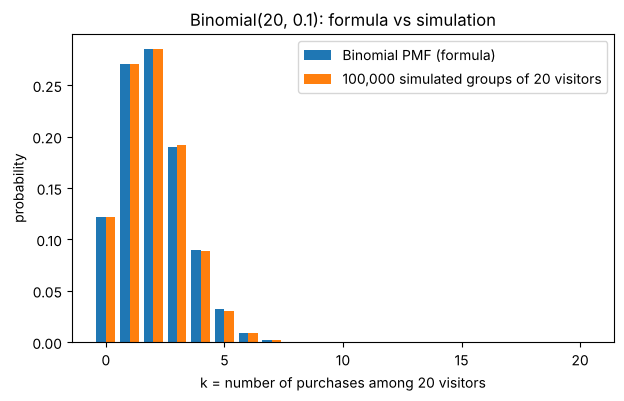


Multinomial: P(7, 2, 1) formula = 0.1186   simulated = 0.1179
means [6.99628 2.0037  1.00002] vs n*pi = [7. 2. 1.];  Cov(N_bug, N_question) = -1.405 vs -n pi_1 pi_2 = -1.400


In [4]:
def binom_pmf(k, n, p):
    return comb(n, k) * p**k * (1 - p) ** (n - k)

n, p = 20, 0.1
ks = np.arange(0, n + 1)
pmf_hand = np.array([binom_pmf(k, n, p) for k in ks])
print("max |hand - scipy| over all k:", np.abs(pmf_hand - stats.binom.pmf(ks, n, p)).max())
print(f"P(S <= 2) = {pmf_hand[:3].sum():.4f}    P(S >= 3) = {pmf_hand[3:].sum():.4f}    P(S >= 5) = {pmf_hand[5:].sum():.4f}")

# simulate the story: 100,000 groups of 20 Bernoulli(0.1) visitors
trials = rng.random((100_000, n)) < p            # Bernoulli(p) as 'uniform < p'
S = trials.sum(axis=1)
emp = np.array([(S == k).mean() for k in ks])
print(f"simulated mean {S.mean():.4f} vs np = {n*p};   simulated var {S.var():.4f} vs np(1-p) = {n*p*(1-p)}")

plt.bar(ks - 0.2, pmf_hand, width=0.4, label="Binomial PMF (formula)")
plt.bar(ks + 0.2, emp, width=0.4, label="100,000 simulated groups of 20 visitors")
plt.xlabel("k = number of purchases among 20 visitors"); plt.ylabel("probability")
plt.title("Binomial(20, 0.1): formula vs simulation"); plt.legend(); plt.show()

# Multinomial: 10 tickets, categories bug / question / feature with probabilities (0.7, 0.2, 0.1)
pi_ = np.array([0.7, 0.2, 0.1])
counts = rng.multinomial(10, pi_, size=100_000)
p_721 = factorial(10) / (factorial(7) * factorial(2) * factorial(1)) * 0.7**7 * 0.2**2 * 0.1
print(f"\nMultinomial: P(7, 2, 1) formula = {p_721:.4f}   simulated = {np.mean(np.all(counts == [7, 2, 1], axis=1)):.4f}")
print(f"means {counts.mean(axis=0)} vs n*pi = {10*pi_};  Cov(N_bug, N_question) = {np.cov(counts[:, 0], counts[:, 1])[0, 1]:.3f} vs -n pi_1 pi_2 = {-10*0.7*0.2:.3f}")

The hand PMF and `scipy.stats.binom` agree to floating-point precision, and the simulation agrees with
both to within Monte Carlo noise ($\pm 0.003$ on each bar). The mean of 2 purchases hides a lot of spread:
3 or more purchases happen in 32% of groups. In the Multinomial the covariance between two categories is
*negative* — a ticket filed as a bug is one that cannot be a question.

**Try it yourself:** change `p` to 0.5 and re-run — the PMF becomes symmetric; then set `n = 200`,
`p = 0.01` and compare the bars with `stats.poisson.pmf(ks, 2)`.

## 3. Geometric and Negative Binomial — waiting for successes

Count the visitors until the first purchase ($p = 0.1$). The guide says $P(X = k) = 0.9^{k-1}\cdot 0.1$,
$\mathbb{E}[X] = 10$, $\operatorname{Var}(X) = 90$, and — memorylessness — $P(X > 8 \mid X > 5) = P(X > 3) = 0.729$.
We simulate the trials literally (keep drawing until a success), then the failures before the *third*
success, whose variance far exceeds its mean: the over-dispersion signature.

In [5]:
p = 0.1
n_sims = 100_000
# trial number of the first success: inverse-CDF for the geometric, equivalent to drawing until success
u = rng.random(n_sims)
X = np.floor(np.log(u) / np.log(1 - p)).astype(int) + 1
print(f"Geometric(0.1): simulated mean {X.mean():.3f} (1/p = 10),  var {X.var():.2f} ((1-p)/p² = 90),  median {np.median(X):.0f} (ln 0.5 / ln 0.9 = {log(0.5)/log(0.9):.2f})")
print(f"P(X = 5) sim {np.mean(X == 5):.4f} vs 0.9^4 * 0.1 = {0.9**4 * 0.1:.4f};   P(X > 10) sim {np.mean(X > 10):.4f} vs 0.9^10 = {0.9**10:.4f}")

# memorylessness by filtering: among runs that survived 5 trials, how many survive 8?
survived5 = X > 5
print(f"memorylessness: P(X > 8 | X > 5) = {np.mean(X[survived5] > 8):.4f}   P(X > 3) = {np.mean(X > 3):.4f}   0.9^3 = {0.9**3:.4f}")

# failures before the 3rd success = sum of three independent (failures-before-success) geometrics
Y = sum(np.floor(np.log(rng.random(n_sims)) / np.log(1 - p)).astype(int) for _ in range(3))
print(f"\nNegBin(r=3, p=0.1): simulated mean {Y.mean():.2f} (27),  var {Y.var():.1f} (270)  ->  var/mean = {Y.var()/Y.mean():.1f}  (Poisson would give 1)")
print(f"P(Y <= 10) sim {np.mean(Y <= 10):.4f}   scipy nbinom.cdf(10, 3, 0.1) = {stats.nbinom.cdf(10, 3, 0.1):.4f}")
print(f"P(Y = 0) sim {np.mean(Y == 0):.4f}   0.1^3 = {0.1**3:.4f}")

Geometric(0.1): simulated mean 9.961 (1/p = 10),  var 88.81 ((1-p)/p² = 90),  median 7 (ln 0.5 / ln 0.9 = 6.58)
P(X = 5) sim 0.0665 vs 0.9^4 * 0.1 = 0.0656;   P(X > 10) sim 0.3478 vs 0.9^10 = 0.3487
memorylessness: P(X > 8 | X > 5) = 0.7266   P(X > 3) = 0.7307   0.9^3 = 0.7290

NegBin(r=3, p=0.1): simulated mean 27.00 (27),  var 268.2 (270)  ->  var/mean = 9.9  (Poisson would give 1)
P(Y <= 10) sim 0.1340   scipy nbinom.cdf(10, 3, 0.1) = 0.1339
P(Y = 0) sim 0.0009   0.1^3 = 0.0010


Conditioning on "no success in the first 5 trials" and then asking about 3 *further* failures gives the
same probability as asking about 3 failures from scratch — the trials have no memory, so a machine that has
run clean for 60 days is not "overdue". The Negative Binomial's variance-to-mean ratio of 10 is what real
count data (claims, reads, clicks) often look like; a Poisson model of such counts would be badly
over-confident.

## 4. Poisson — the limit of many rare trials, and the Poisson process

$P(N = k) = e^{-\lambda}\lambda^k/k!$ with mean and variance both $\lambda$. We implement the PMF, then
watch $\text{Binomial}(n, \lambda/n)$ converge to $\text{Poisson}(\lambda)$ as $n$ grows with the mean held
at $\lambda = 3$, and finally simulate a Poisson *process*: Exponential gaps between calls, counted per hour.

max |hand - scipy|: 9.71445146547012e-17
P(N >= 4) = 0.3528  (1 - 13 e^-3 = 0.3528)

     n   p = λ/n   max_k |Binomial - Poisson|
     5    0.6000                      0.12156
    10    0.3000                      0.04279
    30    0.1000                      0.01205
   180    0.0167                      0.00189
  1000    0.0030                      0.00034


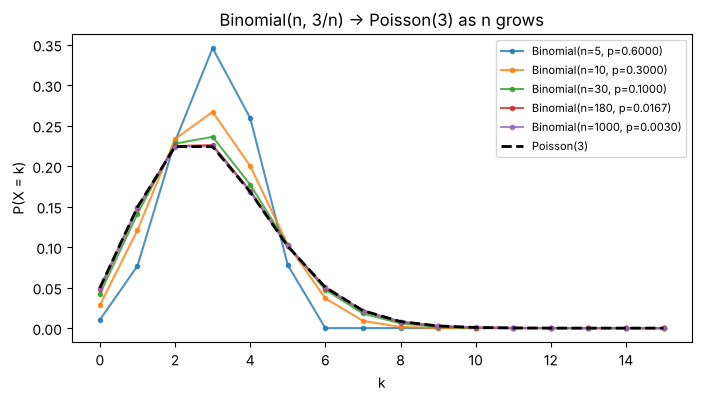

In [6]:
def poisson_pmf(k, lam):
    return exp(-lam) * lam**k / factorial(k)

lam = 3
ks = np.arange(0, 16)
pmf_p = np.array([poisson_pmf(k, lam) for k in ks])
print("max |hand - scipy|:", np.abs(pmf_p - stats.poisson.pmf(ks, lam)).max())
print(f"P(N >= 4) = {pmf_p[4:].sum():.4f}  (1 - 13 e^-3 = {1 - 13*exp(-3):.4f})")

fig, ax = plt.subplots(figsize=(8, 4))
print(f"\n{'n':>6s} {'p = λ/n':>9s} {'max_k |Binomial - Poisson|':>28s}")
for n in (5, 10, 30, 180, 1000):
    pb = stats.binom.pmf(ks, n, lam / n)
    ax.plot(ks, pb, "o-", ms=3, alpha=0.8, label=f"Binomial(n={n}, p={lam/n:.4f})")
    print(f"{n:6d} {lam/n:9.4f} {np.abs(pb - pmf_p).max():28.5f}")
ax.plot(ks, pmf_p, "k--", lw=2, label="Poisson(3)")
ax.set_xlabel("k"); ax.set_ylabel("P(X = k)"); ax.set_title("Binomial(n, 3/n) → Poisson(3) as n grows")
ax.legend(fontsize=8); plt.show()

In [7]:
# A Poisson process at rate 3 per hour: exponential gaps, counted per hour over 20,000 hours
rate = 3.0
hours = 20_000
gaps = rng.exponential(1 / rate, size=int(rate * hours * 1.2))   # more than enough gaps
arrivals = np.cumsum(gaps)
arrivals = arrivals[arrivals < hours]
counts = np.bincount(arrivals.astype(int), minlength=hours)      # calls in each hour
print(f"calls per hour: mean {counts.mean():.3f}, var {counts.var():.3f}  (Poisson: both = 3)")
emp = np.array([(counts == k).mean() for k in ks])
print("max |empirical - Poisson(3) pmf|:", np.abs(emp - pmf_p).max())
print(f"gaps between calls (minutes): mean {60*gaps.mean():.2f} (20),  P(gap > 30 min) = {np.mean(gaps > 0.5):.4f} (e^-1.5 = {exp(-1.5):.4f})")
# thinning: keep each call independently with probability 1/3 -> Poisson process of rate 1
kept = arrivals[rng.random(arrivals.size) < 1/3]
kc = np.bincount(kept.astype(int), minlength=hours)
print(f"thinned (keep 1/3): mean {kc.mean():.3f}, var {kc.var():.3f}  (Poisson(1))")

calls per hour: mean 2.993, var 3.004  (Poisson: both = 3)
max |empirical - Poisson(3) pmf|: 0.003488794896408187
gaps between calls (minutes): mean 20.06 (20),  P(gap > 30 min) = 0.2226 (e^-1.5 = 0.2231)
thinned (keep 1/3): mean 0.998, var 0.995  (Poisson(1))


At $n = 180$ (the guide's "180 customers each calling with probability 1/60") the largest gap between the
Binomial and the Poisson PMF is below $0.002$; by $n = 1000$ it is below $0.0004$. The process simulation
closes the loop between Sections 4 and 5: Exponential gaps *produce* Poisson counts with mean equal to
variance, and thinning the stream at random keeps it Poisson.

**Try it yourself:** replace the Exponential gaps by `rng.uniform(0, 2/rate, size=...)` (same mean gap,
but regular) and look at the variance of the hourly counts — it collapses well below the mean, because
regular arrivals are *under*-dispersed.

## 5. Uniform and Exponential — inverse-CDF sampling and memorylessness

If $U \sim \text{Uniform}(0, 1)$ then $T = -\ln(U)/\lambda$ has $P(T > t) = P(U < e^{-\lambda t}) = e^{-\lambda t}$:
it is $\text{Exponential}(\lambda)$. We sample this way (no `rng.exponential`), compare the histogram with
$\lambda e^{-\lambda t}$, read off the median and 90th percentile, check memorylessness by filtering, and
estimate the hazard rate $h(t) = f(t)/P(T > t)$ from the sample — it should be flat.

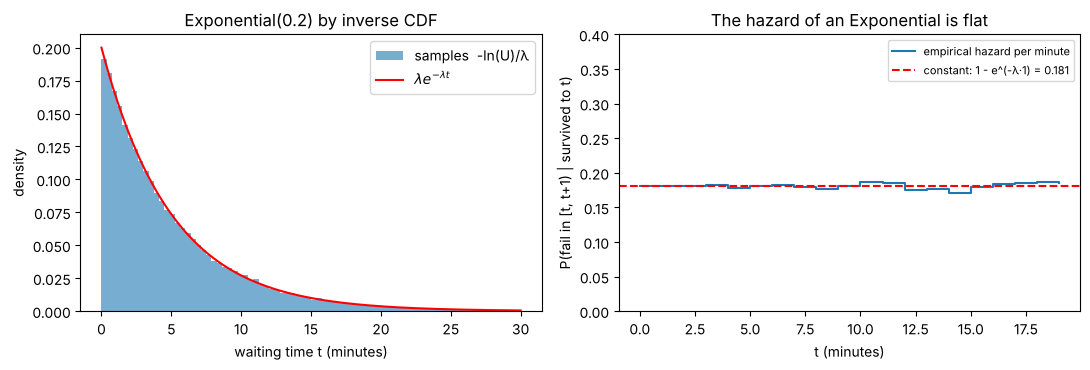

mean 5.017 (5),  sd 5.034 (5),  median 3.470 (ln2/λ = 3.466),  90th pct 11.52 (-ln(0.1)/λ = 11.51)
P(T > 5) = 0.3691 (e^-1 = 0.3679);   P(2 < T < 4) = 0.2213 (0.2210)
memorylessness: P(T > 10 | T > 5) = 0.3703   vs   P(T > 5) = 0.3691
scipy: expon(scale=1/lam).ppf(0.9) = 11.51;  rng.exponential(1/lam) gives the same distribution


In [8]:
lam = 0.2                                   # buses: one every 5 minutes on average
u = rng.random(100_000)
T = -np.log(u) / lam                        # inverse-CDF sampling

grid = np.linspace(0, 30, 300)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.hist(T, bins=80, range=(0, 30), density=True, alpha=0.6, label="samples  -ln(U)/λ")
ax1.plot(grid, lam * np.exp(-lam * grid), "r", label=r"$\lambda e^{-\lambda t}$")
ax1.set_xlabel("waiting time t (minutes)"); ax1.set_ylabel("density"); ax1.set_title("Exponential(0.2) by inverse CDF"); ax1.legend()

# empirical hazard: fraction of survivors at t that 'fail' in the next dt, divided by dt
edges = np.arange(0, 20, 1.0)
haz = [np.mean((T >= a) & (T < a + 1)) / np.mean(T >= a) for a in edges]
ax2.step(edges, haz, where="post", label="empirical hazard per minute")
ax2.axhline(1 - exp(-lam), color="r", ls="--", label=f"constant: 1 - e^(-λ·1) = {1-exp(-lam):.3f}")
ax2.set_ylim(0, 0.4); ax2.set_xlabel("t (minutes)"); ax2.set_ylabel("P(fail in [t, t+1) | survived to t)")
ax2.set_title("The hazard of an Exponential is flat"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"mean {T.mean():.3f} (5),  sd {T.std():.3f} (5),  median {np.median(T):.3f} (ln2/λ = {log(2)/lam:.3f}),  90th pct {np.quantile(T, 0.9):.2f} (-ln(0.1)/λ = {-log(0.1)/lam:.2f})")
print(f"P(T > 5) = {np.mean(T > 5):.4f} (e^-1 = {exp(-1):.4f});   P(2 < T < 4) = {np.mean((T > 2) & (T < 4)):.4f} ({exp(-0.4)-exp(-0.8):.4f})")
print(f"memorylessness: P(T > 10 | T > 5) = {np.mean(T[T > 5] > 10):.4f}   vs   P(T > 5) = {np.mean(T > 5):.4f}")
print(f"scipy: expon(scale=1/lam).ppf(0.9) = {stats.expon(scale=1/lam).ppf(0.9):.2f};  rng.exponential(1/lam) gives the same distribution")

The hazard plot is the real content: for an Exponential, the chance of the event in the next minute does
not depend on how long you have already waited. Any lifetime whose hazard rises with age (tyres, bearings)
or falls (infant mortality of electronics) is *not* Exponential, and the plot would show a slope.
The median $3.47$ sits well below the mean $5$ — a skewed distribution's typical value is not its mean.

## 6. The Normal — 68–95–99.7, standardisation, a Q–Q plot, and sums

Heights $\sim \mathcal{N}(165, 7^2)$. We check the 68–95–99.7 rule on samples, compute $P(X > 180)$ by
standardising, verify that the *sum* of two independent Normals is exactly Normal, and draw a **Q–Q plot**:
sorted sample quantiles against the theoretical Normal quantiles. Points on the diagonal mean "Normal";
the same plot for Exponential and Student-t data shows what skew and heavy tails look like.

In [9]:
mu, sd = 165, 7
X = rng.normal(mu, sd, 100_000)
for k in (1, 2, 3):
    print(f"P(|X - μ| <= {k}σ): sample {np.mean(np.abs(X - mu) <= k*sd):.4f}   exact {stats.norm.cdf(k) - stats.norm.cdf(-k):.4f}")
z = (180 - mu) / sd
print(f"\nP(X > 180): z = {z:.3f}, 1 - Φ(z) = {stats.norm.sf(z):.4f}, sample {np.mean(X > 180):.4f}")
print(f"99th percentile: μ + 2.326σ = {mu + stats.norm.ppf(0.99)*sd:.2f}, sample {np.quantile(X, 0.99):.2f}")

# sums of independent Normals are exactly Normal
Y = rng.normal(mu, sd, 100_000)
S = X + Y
print(f"\nX + Y: mean {S.mean():.2f} (330), var {S.var():.1f} (98);  P(S > 345) sample {np.mean(S > 345):.4f} vs N(330, 98): {stats.norm.sf(345, 330, sqrt(98)):.4f}")

# log-normal: mean is e^(mu + sigma^2/2), not e^mu
L = np.exp(rng.normal(log(50_000), 0.5, 100_000))
print(f"\nlog-normal income: median {np.median(L):,.0f} (50,000), mean {L.mean():,.0f} (e^(μ+σ²/2) = {50_000*exp(0.125):,.0f}), P(> 100k) = {np.mean(L > 100_000):.4f} ({stats.norm.sf(log(2)/0.5):.4f})")

P(|X - μ| <= 1σ): sample 0.6845   exact 0.6827
P(|X - μ| <= 2σ): sample 0.9533   exact 0.9545
P(|X - μ| <= 3σ): sample 0.9969   exact 0.9973

P(X > 180): z = 2.143, 1 - Φ(z) = 0.0161, sample 0.0164
99th percentile: μ + 2.326σ = 181.28, sample 181.31

X + Y: mean 330.02 (330), var 98.4 (98);  P(S > 345) sample 0.0654 vs N(330, 98): 0.0649

log-normal income: median 50,062 (50,000), mean 56,666 (e^(μ+σ²/2) = 56,657), P(> 100k) = 0.0831 (0.0828)


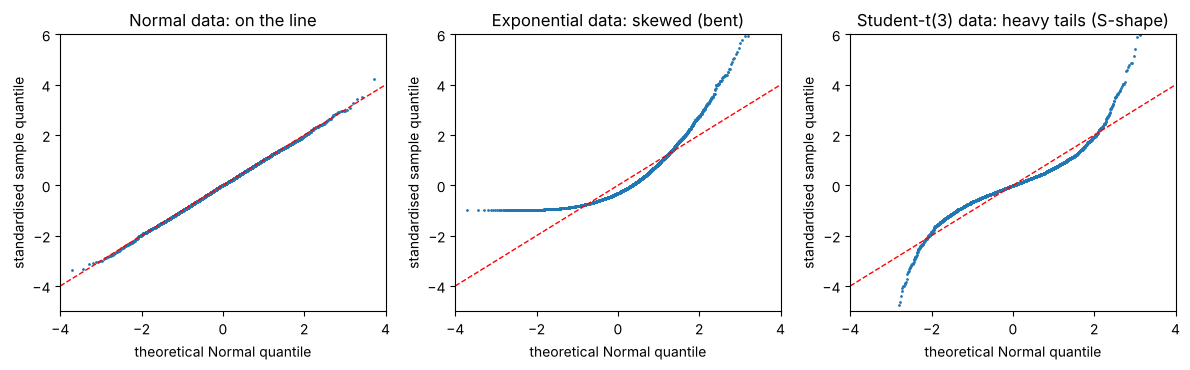

In [10]:
def qq_plot(ax, sample, title):
    s = np.sort(sample)
    n = len(s)
    probs = (np.arange(1, n + 1) - 0.5) / n
    theo = stats.norm.ppf(probs)
    zs = (s - s.mean()) / s.std()
    ax.plot(theo, zs, ".", ms=2)
    ax.plot([-4, 4], [-4, 4], "r--", lw=1)
    ax.set_xlim(-4, 4); ax.set_ylim(-5, 6)
    ax.set_xlabel("theoretical Normal quantile"); ax.set_ylabel("standardised sample quantile"); ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
qq_plot(axes[0], rng.normal(size=5000), "Normal data: on the line")
qq_plot(axes[1], rng.exponential(size=5000), "Exponential data: skewed (bent)")
qq_plot(axes[2], rng.standard_t(3, size=5000), "Student-t(3) data: heavy tails (S-shape)")
plt.tight_layout(); plt.show()

In the Q–Q plot a right-skewed sample bends upward on the right (its large quantiles are larger than a
Normal's) and a heavy-tailed sample peels away at *both* ends. This is the single most useful diagnostic
before you trust a Gaussian assumption — on residuals of a regression, on the per-example losses of a
model, or on the sampling distribution of a metric.

**Try it yourself:** feed `np.log(L)` (the log of the log-normal incomes) into `qq_plot` — the log
transform turns the skewed sample into a straight line.

## 7. Gamma, Beta, Chi-square and Student-t — built from their ingredients

Each of these is *made of* simpler pieces: the Gamma($k$, $\lambda$) is a sum of $k$ Exponentials, the
Chi-square($k$) is a sum of $k$ squared standard Normals, and the Student-t($\nu$) is $Z/\sqrt{V/\nu}$. We
construct each one from its ingredients and overlay the `scipy.stats` density. Then the Beta: a grid of
shapes, and the posterior $\text{Beta}(2 + 7, 2 + 43)$ for a conversion rate after 7 successes in 50 trials.

Gamma: mean 14.98 (15), sd 8.63 (8.66), P(> 20) = 0.2363  (= P(Poisson(4) <= 2) = 0.2381)
Chi-square(4): mean 3.986 (4), var 7.96 (8), 95th pct 9.441 (scipy 9.488)
Student-t(3): P(|T| > 3) = 0.0582 (exact 0.0577);  Normal: 0.0027  ->  ratio 21.4x
t quantiles 97.5%: ν=4 2.776, ν=9 2.262, ν=29 2.045, Normal 1.960


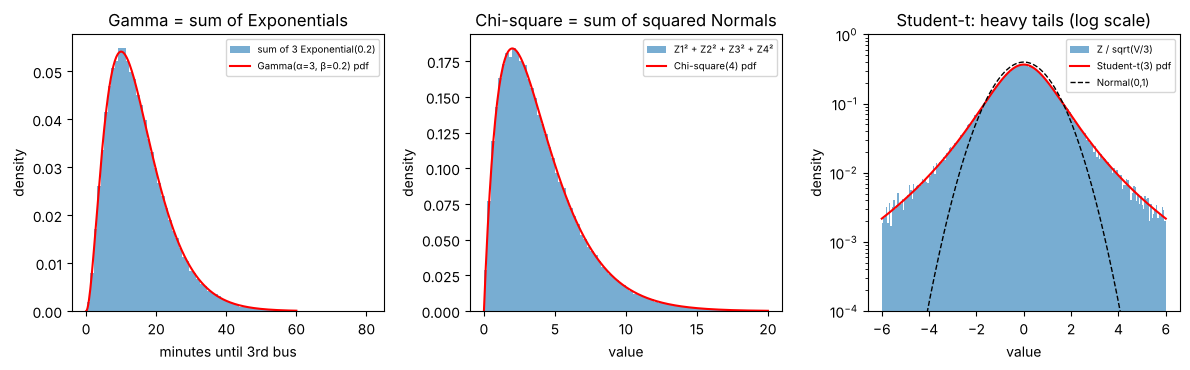

In [11]:
n_s = 100_000
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))

# Gamma(3, rate 0.2) = sum of three Exponential(0.2): time until the third bus
G = rng.exponential(1 / 0.2, size=(n_s, 3)).sum(axis=1)
xg = np.linspace(0, 60, 300)
axes[0].hist(G, bins=80, density=True, alpha=0.6, label="sum of 3 Exponential(0.2)")
axes[0].plot(xg, stats.gamma.pdf(xg, a=3, scale=1 / 0.2), "r", label="Gamma(α=3, β=0.2) pdf")
axes[0].set_title("Gamma = sum of Exponentials"); axes[0].set_xlabel("minutes until 3rd bus")
print(f"Gamma: mean {G.mean():.2f} (15), sd {G.std():.2f} ({sqrt(3)/0.2:.2f}), P(> 20) = {np.mean(G > 20):.4f}  (= P(Poisson(4) <= 2) = {stats.poisson.cdf(2, 4):.4f})")

# Chi-square(4) = sum of four squared standard Normals
C = (rng.normal(size=(n_s, 4)) ** 2).sum(axis=1)
xc = np.linspace(0, 20, 300)
axes[1].hist(C, bins=80, range=(0, 20), density=True, alpha=0.6, label="Z1² + Z2² + Z3² + Z4²")
axes[1].plot(xc, stats.chi2.pdf(xc, 4), "r", label="Chi-square(4) pdf")
axes[1].set_title("Chi-square = sum of squared Normals"); axes[1].set_xlabel("value")
print(f"Chi-square(4): mean {C.mean():.3f} (4), var {C.var():.2f} (8), 95th pct {np.quantile(C, 0.95):.3f} (scipy {stats.chi2.ppf(0.95, 4):.3f})")

# Student-t(3) = Z / sqrt(V/3)
Z = rng.normal(size=n_s); V = (rng.normal(size=(n_s, 3)) ** 2).sum(axis=1)
Tt = Z / np.sqrt(V / 3)
xt = np.linspace(-6, 6, 300)
axes[2].hist(Tt, bins=200, range=(-6, 6), density=True, alpha=0.6, label="Z / sqrt(V/3)")
axes[2].plot(xt, stats.t.pdf(xt, 3), "r", label="Student-t(3) pdf")
axes[2].plot(xt, stats.norm.pdf(xt), "k--", lw=1, label="Normal(0,1)")
axes[2].set_yscale("log"); axes[2].set_ylim(1e-4, 1); axes[2].set_title("Student-t: heavy tails (log scale)"); axes[2].set_xlabel("value")
print(f"Student-t(3): P(|T| > 3) = {np.mean(np.abs(Tt) > 3):.4f} (exact {2*stats.t.sf(3, 3):.4f});  Normal: {2*stats.norm.sf(3):.4f}  ->  ratio {stats.t.sf(3, 3)/stats.norm.sf(3):.1f}x")
print(f"t quantiles 97.5%: ν=4 {stats.t.ppf(0.975, 4):.3f}, ν=9 {stats.t.ppf(0.975, 9):.3f}, ν=29 {stats.t.ppf(0.975, 29):.3f}, Normal {stats.norm.ppf(0.975):.3f}")
for ax in axes:
    ax.legend(fontsize=7); ax.set_ylabel("density")
plt.tight_layout(); plt.show()

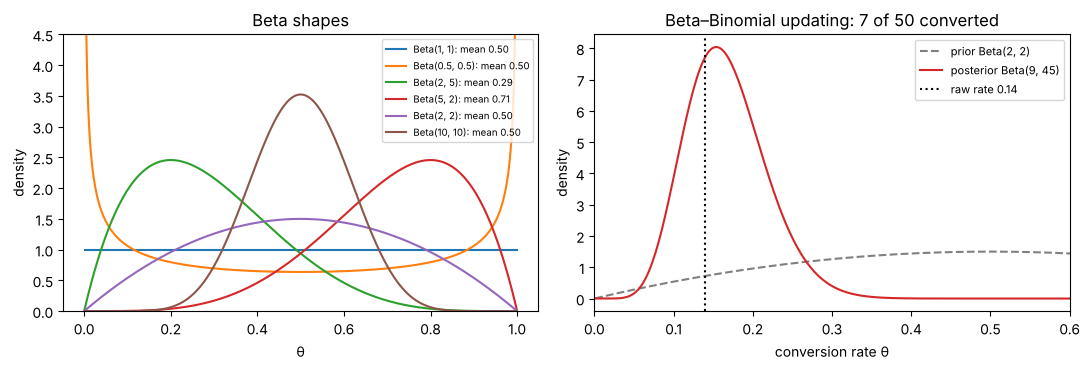

posterior mean 0.1667 (9/54), sd 0.0503, mode 0.1538
P(θ > 0.2 | data) = 0.2408;   95% credible interval 0.081 – 0.276
grid check of the density at θ=0.15: 8.002 vs scipy 8.016
P(θ_B > θ_A) = 0.885


In [12]:
# Beta shapes, and a Beta posterior for a conversion rate
theta = np.linspace(0.001, 0.999, 500)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
for a, b in [(1, 1), (0.5, 0.5), (2, 5), (5, 2), (2, 2), (10, 10)]:
    ax1.plot(theta, stats.beta.pdf(theta, a, b), label=f"Beta({a}, {b}): mean {a/(a+b):.2f}")
ax1.set_ylim(0, 4.5); ax1.set_xlabel("θ"); ax1.set_ylabel("density"); ax1.set_title("Beta shapes"); ax1.legend(fontsize=7)

# prior Beta(2, 2); data: 7 conversions in 50 visits; posterior Beta(9, 45)
a0, b0, s, f = 2, 2, 7, 43
post = stats.beta(a0 + s, b0 + f)
ax2.plot(theta, stats.beta.pdf(theta, a0, b0), "gray", ls="--", label="prior Beta(2, 2)")
ax2.plot(theta, post.pdf(theta), "C3", label=f"posterior Beta({a0+s}, {b0+f})")
ax2.axvline(s / (s + f), color="k", ls=":", label=f"raw rate {s/(s+f):.2f}")
ax2.set_xlim(0, 0.6); ax2.set_xlabel("conversion rate θ"); ax2.set_ylabel("density"); ax2.set_title("Beta–Binomial updating: 7 of 50 converted"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"posterior mean {post.mean():.4f} (9/54), sd {post.std():.4f}, mode {(a0+s-1)/(a0+s+b0+f-2):.4f}")
print(f"P(θ > 0.2 | data) = {post.sf(0.2):.4f};   95% credible interval {post.ppf(0.025):.3f} – {post.ppf(0.975):.3f}")
# the posterior IS the normalised likelihood x prior: check numerically on the grid
unnorm = theta**(a0 + s - 1) * (1 - theta)**(b0 + f - 1)
print(f"grid check of the density at θ=0.15: {unnorm[np.argmin(np.abs(theta-0.15))] / np.trapezoid(unnorm, theta):.3f} vs scipy {post.pdf(0.15):.3f}")

# Bayesian A/B: page B converted 12 of 50 -> Beta(14, 40); P(θ_B > θ_A) by sampling both posteriors
a_s = rng.beta(9, 45, 200_000); b_s = rng.beta(14, 40, 200_000)
print(f"P(θ_B > θ_A) = {np.mean(b_s > a_s):.3f}")

The Gamma histogram built from three Exponentials sits exactly on `gamma.pdf`, and its tail probability
$P(G > 20)$ equals the Poisson probability of at most 2 arrivals in 20 minutes — the same event described
twice. On the log scale the Student-t(3) tails are visibly straight lines (power law) while the Normal's
curve down (Gaussian): beyond 3 standard units the $t_3$ has 21 times the mass. The Beta posterior
has simply added the counts to the prior parameters; the result is a full distribution for the conversion
rate, from which "probability the rate exceeds 20%" or "probability B beats A" are one line each.

## 8. Moments, an MGF identity, and heavy tails

Skewness $\gamma_1 = \mathbb{E}[(X-\mu)^3]/\sigma^3$ and excess kurtosis $\gamma_2 = \mathbb{E}[(X-\mu)^4]/\sigma^4 - 3$
from samples; the MGF $M(t) = \mathbb{E}[e^{tX}]$ estimated by averaging $e^{tX}$ and compared with the
closed form $e^{\lambda(e^t - 1)}$ for the Poisson; the sum of two Poissons checked against
$\text{Poisson}(\lambda_1 + \lambda_2)$; and a look at how a Pareto tail differs from an Exponential tail
with the *same mean*.

In [13]:
def skew_kurt(x):
    z = (x - x.mean()) / x.std()
    return np.mean(z**3), np.mean(z**4) - 3

samples = {
    "Normal":            rng.normal(size=200_000),
    "Uniform":           rng.random(200_000),
    "Exponential":       rng.exponential(size=200_000),
    "Bernoulli(0.1)":    (rng.random(200_000) < 0.1).astype(float),
    "Poisson(3)":        rng.poisson(3, 200_000).astype(float),
    "Student-t(5)":      rng.standard_t(5, 200_000),
}
theory = {"Normal": (0, 0), "Uniform": (0, -1.2), "Exponential": (2, 6), "Bernoulli(0.1)": ((1 - 0.2) / sqrt(0.09), (1 - 6 * 0.09) / 0.09),
          "Poisson(3)": (1 / sqrt(3), 1 / 3), "Student-t(5)": (0, 6)}
print(f"{'distribution':16s} {'skew (sample)':>14s} {'skew (theory)':>14s} {'kurt (sample)':>14s} {'kurt (theory)':>14s}")
for name, x in samples.items():
    s, k = skew_kurt(x); ts, tk = theory[name]
    print(f"{name:16s} {s:14.3f} {ts:14.3f} {k:14.3f} {tk:14.3f}")

# MGF of Poisson(3): E[e^{tX}] vs exp(lam (e^t - 1)); and the sum of Poisson(2) + Poisson(3)
N3 = samples["Poisson(3)"]
for t in (0.1, 0.25, 0.5):
    print(f"t = {t}: mean of e^(tX) = {np.mean(np.exp(t * N3)):.4f}   exp(3(e^t - 1)) = {exp(3 * (exp(t) - 1)):.4f}")
N2 = rng.poisson(2, 200_000)
S = N2 + N3.astype(int)
ks = np.arange(0, 16)
print("\nmax |empirical pmf of Poisson(2)+Poisson(3)  -  Poisson(5) pmf| =",
      np.abs(np.array([(S == k).mean() for k in ks]) - stats.poisson.pmf(ks, 5)).max())

distribution      skew (sample)  skew (theory)  kurt (sample)  kurt (theory)
Normal                    0.006          0.000         -0.008          0.000
Uniform                   0.001          0.000         -1.203         -1.200
Exponential               2.019          2.000          6.262          6.000
Bernoulli(0.1)            2.660          2.667          5.078          5.111


Poisson(3)                0.577          0.577          0.318          0.333
Student-t(5)              0.008          0.000          5.192          6.000
t = 0.1: mean of e^(tX) = 1.3711   exp(3(e^t - 1)) = 1.3710
t = 0.25: mean of e^(tX) = 2.3452   exp(3(e^t - 1)) = 2.3445
t = 0.5: mean of e^(tX) = 7.0003   exp(3(e^t - 1)) = 7.0018



max |empirical pmf of Poisson(2)+Poisson(3)  -  Poisson(5) pmf| = 0.0015088958142805142


means: Exponential 3.009, Pareto 2.940  (both 3 in theory)
P(X > 30):  Exponential 5.00e-05 (e^-10 = 4.54e-05),  Pareto 6.13e-03 (30^-1.5 = 6.09e-03)
P(X > 300): Exponential 0.0e+00 (e^-100),           Pareto 1.85e-04 (300^-1.5 = 1.92e-04)
largest of 200000 samples: Exponential 37.2, Pareto 2567;  share of total in the top 1%: Exponential 0.056, Pareto 0.201
sample kurtosis: Exponential 6.0 (6),  Pareto 12139 (infinite: it grows with n and never settles)


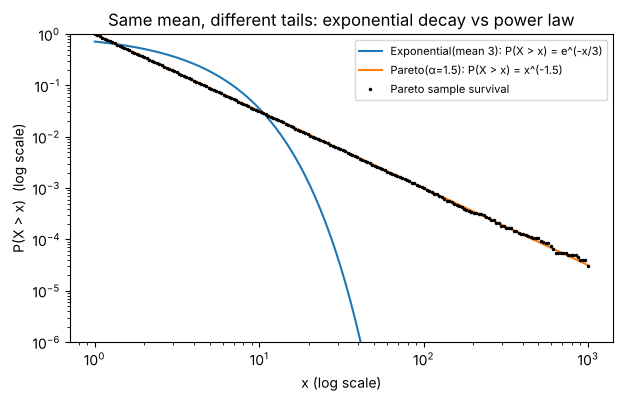

In [14]:
# light vs heavy tails with the same mean 3: Exponential(mean 3) vs Pareto(alpha=1.5, x_min=1)
n = 200_000
E = rng.exponential(3.0, n)
P = (rng.pareto(1.5, n) + 1.0)           # numpy's pareto is the Lomax; +1 gives the classical Pareto with x_min = 1
print(f"means: Exponential {E.mean():.3f}, Pareto {P.mean():.3f}  (both 3 in theory)")
print(f"P(X > 30):  Exponential {np.mean(E > 30):.2e} (e^-10 = {exp(-10):.2e}),  Pareto {np.mean(P > 30):.2e} (30^-1.5 = {30**-1.5:.2e})")
print(f"P(X > 300): Exponential {np.mean(E > 300):.1e} (e^-100),           Pareto {np.mean(P > 300):.2e} (300^-1.5 = {300**-1.5:.2e})")
print(f"largest of {n} samples: Exponential {E.max():.1f}, Pareto {P.max():.0f};  share of total in the top 1%: Exponential {np.sort(E)[-n//100:].sum()/E.sum():.3f}, Pareto {np.sort(P)[-n//100:].sum()/P.sum():.3f}")
print(f"sample kurtosis: Exponential {skew_kurt(E)[1]:.1f} (6),  Pareto {skew_kurt(P)[1]:.0f} (infinite: it grows with n and never settles)")

xs = np.logspace(0, 3, 200)
plt.loglog(xs, np.exp(-xs / 3), label="Exponential(mean 3): P(X > x) = e^(-x/3)")
plt.loglog(xs, xs ** -1.5, label="Pareto(α=1.5): P(X > x) = x^(-1.5)")
plt.loglog(xs, [np.mean(P > x) for x in xs], "k.", ms=3, label="Pareto sample survival")
plt.ylim(1e-6, 1); plt.xlabel("x (log scale)"); plt.ylabel("P(X > x)  (log scale)")
plt.title("Same mean, different tails: exponential decay vs power law"); plt.legend(fontsize=8); plt.show()

The sample skewness and kurtosis match the theory for every light-tailed distribution (the Student-t(5)
kurtosis is the noisiest: its population value 6 exists, but the *variance of the estimate* involves the
eighth moment, which the $t_5$ does not have, so even 200,000 samples leave it a little off); for the Pareto
the sample kurtosis is a number that *grows with the sample size* because the population value is infinite. On
the log–log survival plot a power law is a straight line and an exponential plunges: the Pareto puts
$2 \times 10^{-4}$ of its mass beyond 100 times its mean, where the Exponential puts $e^{-100}$. The MGF
check confirms $\mathbb{E}[e^{tN}] = e^{\lambda(e^t - 1)}$, and the sum of two independent Poissons is
indistinguishable from a Poisson with the summed rate — the MGF proof in the guide made concrete.

## 9. The law of large numbers — running averages, and the Cauchy exception

$P(|\bar X_n - \mu| \ge \varepsilon) \le \sigma^2/(n\varepsilon^2)$. We plot the running average of
Exponential(1) samples for several seeds together with the Chebyshev band and the (much tighter) CLT band,
then do the same for a Cauchy sample, whose mean does not exist — the running average never settles.

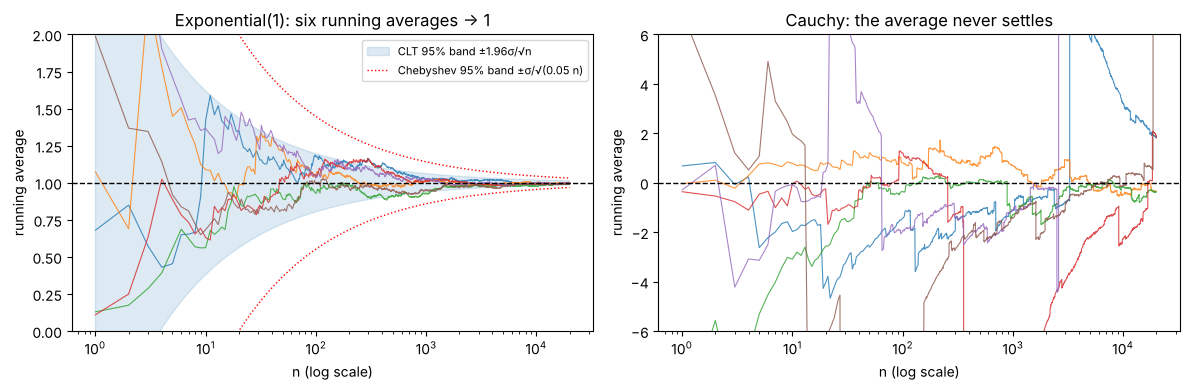

after    100 flips: sd of (heads - n/2) =   5.07 (√n/2 =   5.00);   sd of proportion = 0.0507 (1/(2√n) = 0.0500)
after   1000 flips: sd of (heads - n/2) =  15.88 (√n/2 =  15.81);   sd of proportion = 0.0159 (1/(2√n) = 0.0158)
after  10000 flips: sd of (heads - n/2) =  47.91 (√n/2 =  50.00);   sd of proportion = 0.0048 (1/(2√n) = 0.0050)


In [15]:
n = 20_000
ns = np.arange(1, n + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for seed in range(6):
    r = np.random.default_rng(seed)
    ax1.plot(ns, np.cumsum(r.exponential(1.0, n)) / ns, lw=0.8, alpha=0.8)
    ax2.plot(ns, np.cumsum(r.standard_cauchy(n)) / ns, lw=0.8, alpha=0.8)
ax1.axhline(1, color="k", ls="--", lw=1)
ax1.fill_between(ns, 1 - 1.96 / np.sqrt(ns), 1 + 1.96 / np.sqrt(ns), color="C0", alpha=0.15, label="CLT 95% band ±1.96σ/√n")
ax1.plot(ns, 1 + np.sqrt(1 / (ns * 0.05)), "r:", lw=1, label="Chebyshev 95% band ±σ/√(0.05 n)")
ax1.plot(ns, 1 - np.sqrt(1 / (ns * 0.05)), "r:", lw=1)
ax1.set_xscale("log"); ax1.set_ylim(0, 2); ax1.set_xlabel("n (log scale)"); ax1.set_ylabel("running average")
ax1.set_title("Exponential(1): six running averages → 1"); ax1.legend(fontsize=8, loc="upper right")
ax2.set_xscale("log"); ax2.set_ylim(-6, 6); ax2.axhline(0, color="k", ls="--", lw=1)
ax2.set_xlabel("n (log scale)"); ax2.set_ylabel("running average"); ax2.set_title("Cauchy: the average never settles")
plt.tight_layout(); plt.show()

# the gambler's fallacy in numbers: the proportion converges while the count drifts
flips = rng.integers(0, 2, size=(1000, 10_000))
heads = flips.cumsum(axis=1)
for m in (100, 1_000, 10_000):
    excess = heads[:, m - 1] - m / 2
    print(f"after {m:>6d} flips: sd of (heads - n/2) = {excess.std():6.2f} (√n/2 = {sqrt(m)/2:6.2f});   sd of proportion = {(excess / m).std():.4f} (1/(2√n) = {1/(2*sqrt(m)):.4f})")

Every Exponential trajectory ends inside the CLT band; the Chebyshev band is far wider — it is a guarantee
valid for *any* distribution, paid for with looseness. The Cauchy panel is the warning: each trajectory
is occasionally hit by a sample so large that the average jumps, and no amount of data cures it, because
the mean does not exist. In the coin table the *count* of excess heads grows like $\sqrt{n}/2$ while the
*proportion* shrinks like $1/(2\sqrt{n})$: early luck is diluted, never repaid. (A Student-t with 2
degrees of freedom — finite mean, infinite variance — sits between the two panels: its average converges,
but far more slowly and erratically than the Exponential's.)

## 10. The central limit theorem — how fast, for which source?

$Z_n = \sqrt{n}(\bar X_n - \mu)/\sigma \to \mathcal{N}(0, 1)$. For each of three sources — Uniform
(symmetric), Exponential (skewness 2) and Bernoulli(0.05) (skewness 4.1) — we draw 20,000 means of
$n = 1, 2, 5, 30$ observations, standardise, and overlay the standard Normal. The **Kolmogorov distance**
$\sup_z |F_n(z) - \Phi(z)|$ measures how far each histogram is from the bell, and the Berry–Esseen bound
$0.4748\,\rho/(\sigma^3\sqrt{n})$ says how far it is *allowed* to be.

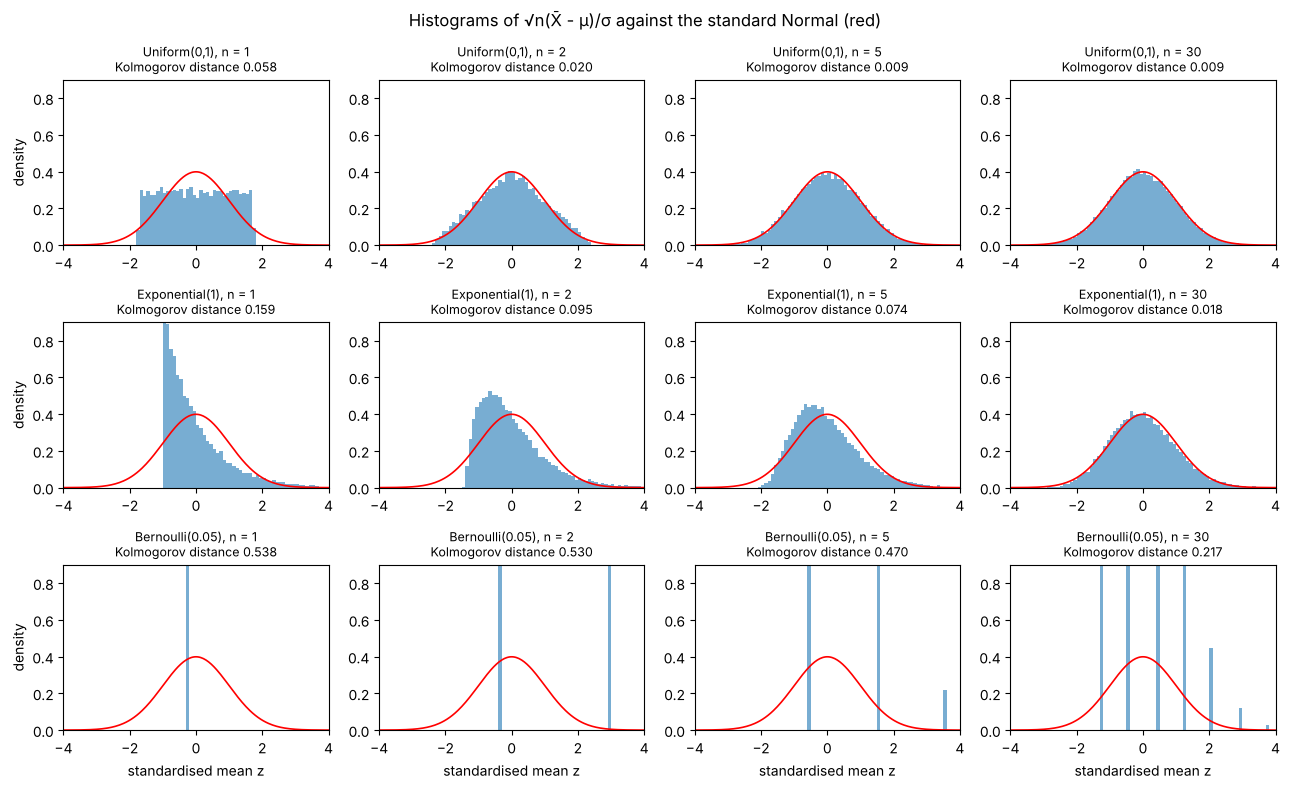

In [16]:
def standardised_means(sampler, n, reps, mu, sigma):
    x = sampler((reps, n)).mean(axis=1)
    return np.sqrt(n) * (x - mu) / sigma

def kolmogorov_distance(z):
    z = np.sort(z); m = len(z); F = stats.norm.cdf(z)
    return max(np.max(np.arange(1, m + 1) / m - F), np.max(F - np.arange(0, m) / m))

p_rare = 0.05
sources = {
    "Uniform(0,1)":     (lambda s: rng.random(s),                        0.5,     sqrt(1 / 12)),
    "Exponential(1)":   (lambda s: rng.exponential(1.0, s),              1.0,     1.0),
    "Bernoulli(0.05)":  (lambda s: (rng.random(s) < p_rare).astype(float), p_rare, sqrt(p_rare * (1 - p_rare))),
}
ns = (1, 2, 5, 30)
reps = 20_000
zgrid = np.linspace(-4, 4, 200)
fig, axes = plt.subplots(3, 4, figsize=(13, 8))
kd = {}
for i, (name, (sampler, mu, sigma)) in enumerate(sources.items()):
    for j, n in enumerate(ns):
        z = standardised_means(sampler, n, reps, mu, sigma)
        kd[(name, n)] = kolmogorov_distance(z)
        ax = axes[i, j]
        ax.hist(z, bins=np.linspace(-4, 4, 81), density=True, alpha=0.6)
        ax.plot(zgrid, stats.norm.pdf(zgrid), "r", lw=1.2)
        ax.set_title(f"{name}, n = {n}\nKolmogorov distance {kd[(name, n)]:.3f}", fontsize=9)
        ax.set_xlim(-4, 4); ax.set_ylim(0, 0.9)
        if j == 0: ax.set_ylabel("density")
        if i == 2: ax.set_xlabel("standardised mean z")
fig.suptitle("Histograms of √n(X̄ - μ)/σ against the standard Normal (red)")
plt.tight_layout(); plt.show()

    n   Uniform  Exponential  BE bound (exp)  Bernoulli(0.05)  BE bound (bern)
    1    0.0613       0.1587          1.1465           0.5404           1.9716
    2    0.0207       0.1016          0.8107           0.5261           1.3941
    5    0.0104       0.0615          0.5127           0.4752           0.8817
   10    0.0047       0.0422          0.3625           0.3627           0.6235
   30    0.0041       0.0248          0.2093           0.2150           0.3600
  100    0.0050       0.0189          0.1146           0.1136           0.1972
  300    0.0050       0.0154          0.0662           0.0687           0.1138


 1000    0.0041       0.0111          0.0363           0.0361           0.0623


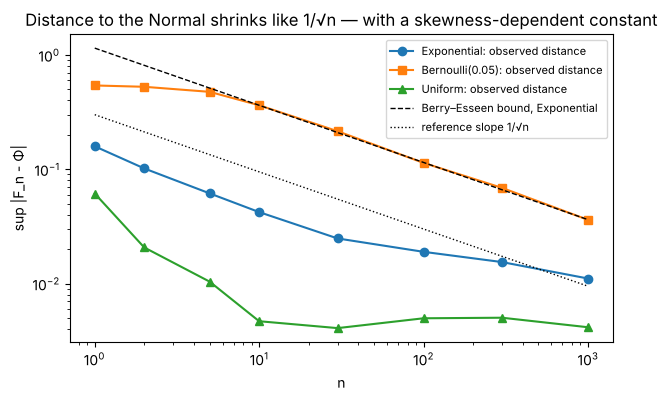


skewness of the source: Uniform 0, Exponential 2, Bernoulli(0.05) 4.13;  of the mean of 30: 0.37 and 0.75
n needed for the skewness of the mean to fall below 0.3: Exponential 44, Bernoulli(0.05) 189, Bernoulli(0.01) 1078


In [17]:
# how fast: Kolmogorov distance vs n, with the Berry-Esseen bound for the exponential source
ns_long = np.array([1, 2, 5, 10, 30, 100, 300, 1000])
rho_exp = 2.4146      # E|X - 1|^3 for Exponential(1)
rho_bern = p_rare * (1 - p_rare) * ((1 - p_rare)**2 + p_rare**2)
sig3_bern = (p_rare * (1 - p_rare)) ** 1.5
print(f"{'n':>5s} {'Uniform':>9s} {'Exponential':>12s} {'BE bound (exp)':>15s} {'Bernoulli(0.05)':>16s} {'BE bound (bern)':>16s}")
rows = []
for n in ns_long:
    d = [kolmogorov_distance(standardised_means(s, n, reps, mu, sg)) for s, mu, sg in sources.values()]
    rows.append(d)
    print(f"{n:5d} {d[0]:9.4f} {d[1]:12.4f} {0.4748*rho_exp/sqrt(n):15.4f} {d[2]:16.4f} {0.4748*rho_bern/sig3_bern/sqrt(n):16.4f}")
rows = np.array(rows)
plt.loglog(ns_long, rows[:, 1], "o-", label="Exponential: observed distance")
plt.loglog(ns_long, rows[:, 2], "s-", label="Bernoulli(0.05): observed distance")
plt.loglog(ns_long, rows[:, 0], "^-", label="Uniform: observed distance")
plt.loglog(ns_long, 0.4748 * rho_exp / np.sqrt(ns_long), "k--", lw=1, label="Berry–Esseen bound, Exponential")
plt.loglog(ns_long, 0.3 / np.sqrt(ns_long), "k:", lw=1, label="reference slope 1/√n")
plt.xlabel("n"); plt.ylabel("sup |F_n - Φ|"); plt.title("Distance to the Normal shrinks like 1/√n — with a skewness-dependent constant")
plt.legend(fontsize=8); plt.show()

skew = lambda p: (1 - 2 * p) / sqrt(p * (1 - p))
print(f"\nskewness of the source: Uniform 0, Exponential 2, Bernoulli(0.05) {skew(0.05):.2f};  of the mean of 30: {2/sqrt(30):.2f} and {skew(0.05)/sqrt(30):.2f}")
print(f"n needed for the skewness of the mean to fall below 0.3: Exponential {(2/0.3)**2:.0f}, Bernoulli(0.05) {(skew(0.05)/0.3)**2:.0f}, Bernoulli(0.01) {(skew(0.01)/0.3)**2:.0f}")

The Uniform is bell-shaped by $n = 2$ (the triangular distribution) and nearly indistinguishable from the
Normal at $n = 5$; from $n = 10$ on its Kolmogorov distance sits at the Monte Carlo noise floor of about
$0.005$ that 20,000 repetitions allow. The Exponential needs $n = 30$ to look symmetric. The Bernoulli(0.05) mean of 30 is still a
comb of spikes (0, 1, 2, 3 successes) and only at $n = 1000$ does it approach the bell. On the log–log
plot every observed curve has slope $-1/2$, and the Berry–Esseen bound sits above the Exponential's
curve with the same slope: the *rate* is universal, the *constant* is set by skewness. This is why "$n = 30$
is enough" is a rule of thumb for roughly symmetric data and a trap for rare events.

**Try it yourself:** set `p_rare = 0.01` and re-run both cells — then read the number of samples a
"significant" A/B test on a 1%-conversion page really needs.

### When the CLT fails: Cauchy means and the polling margin of error

Averages of $n$ Cauchy variables are again Cauchy — the same distribution for every $n$. And on the
success side: a poll of 1,000 voters has a sample proportion that is Normal to high accuracy, so the 95%
margin of error $1.96\sqrt{p(1-p)/n}$ is trustworthy.

In [18]:
# Cauchy: the distribution of the mean of n samples does not depend on n
for n in (1, 10, 100, 1000):
    m = rng.standard_cauchy((20_000, n)).mean(axis=1)
    q = np.quantile(m, [0.25, 0.5, 0.75])
    print(f"n = {n:>5d}: quartiles of the sample mean {q[0]:7.3f} {q[1]:7.3f} {q[2]:7.3f}   (Cauchy quartiles: -1, 0, 1)")

# polling: sample proportion from 1,000 voters, true p = 0.52
p_true, n_poll = 0.52, 1000
props = (rng.random((50_000, n_poll)) < p_true).mean(axis=1)
moe = 1.96 * sqrt(p_true * (1 - p_true) / n_poll)
print(f"\npoll of {n_poll}: sd of the proportion {props.std():.4f} (√(p(1-p)/n) = {sqrt(p_true*(1-p_true)/n_poll):.4f}),  margin of error ±{100*moe:.1f} points")
print(f"coverage of p ± margin: {np.mean(np.abs(props - p_true) <= moe):.4f} (CLT promises 0.95)")
print(f"sample size for a ±2-point margin: n = (1.96 · 0.5 / 0.02)² = {(1.96*0.5/0.02)**2:.0f}")

n =     1: quartiles of the sample mean  -1.001   0.007   1.008   (Cauchy quartiles: -1, 0, 1)
n =    10: quartiles of the sample mean  -1.015  -0.010   1.003   (Cauchy quartiles: -1, 0, 1)
n =   100: quartiles of the sample mean  -1.014  -0.009   0.983   (Cauchy quartiles: -1, 0, 1)


n =  1000: quartiles of the sample mean  -1.041  -0.029   0.948   (Cauchy quartiles: -1, 0, 1)



poll of 1000: sd of the proportion 0.0158 (√(p(1-p)/n) = 0.0158),  margin of error ±3.1 points
coverage of p ± margin: 0.9465 (CLT promises 0.95)
sample size for a ±2-point margin: n = (1.96 · 0.5 / 0.02)² = 2401


The quartiles of the Cauchy sample mean are $-1, 0, 1$ whether you average 1 observation or 1,000: there
is no concentration at all, and any "standard error" computed from such data is a fiction. The poll is the
opposite extreme — a bounded, nearly symmetric source — and the 95% interval covers the truth 95% of
the time, as promised.

## 11. Monte Carlo — error bars that shrink like $1/\sqrt{n}$, and antithetic variates

Estimate $I = \int_0^1 e^{-x^2}\,dx = 0.74682$ as $\mathbb{E}[e^{-U^2}]$ with $U \sim \text{Uniform}(0, 1)$.
For each $n$ we repeat the whole estimate 200 times to measure the actual error, compare it with the
reported standard error $\hat\sigma/\sqrt{n}$, and then use **antithetic variates** — average
$g(U)$ and $g(1-U)$ — to cut the variance without extra samples.

n = 10,000:  estimate 0.74592 ± 0.00201 (standard error),  exact 0.74682,  error -0.00091
antithetic:  estimate 0.74666 ± 0.00040,  error -0.00017   -> variance ratio ≈ 25x


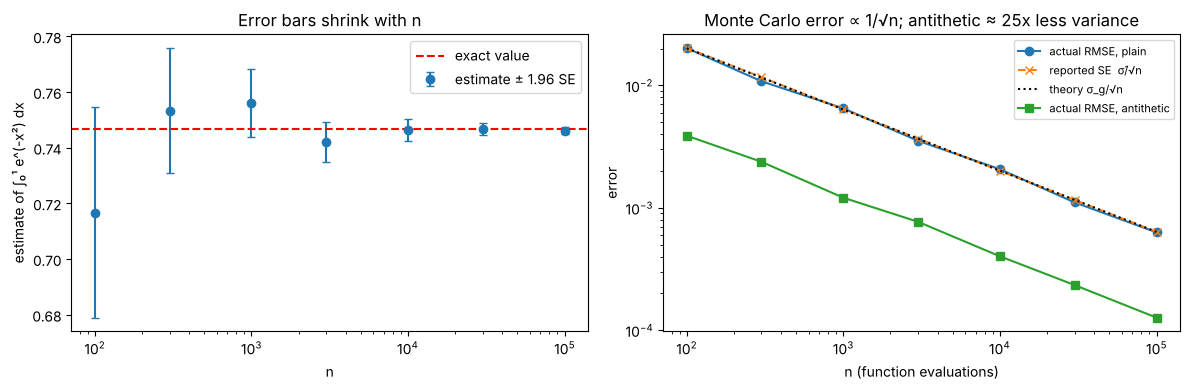

n =     100: RMSE plain 0.02017   reported SE 0.02023   RMSE antithetic 0.00389
n =     300: RMSE plain 0.01081   reported SE 0.01166   RMSE antithetic 0.00238
n =    1000: RMSE plain 0.00649   reported SE 0.00638   RMSE antithetic 0.00121
n =    3000: RMSE plain 0.00353   reported SE 0.00368   RMSE antithetic 0.00077
n =   10000: RMSE plain 0.00207   reported SE 0.00201   RMSE antithetic 0.00040
n =   30000: RMSE plain 0.00111   reported SE 0.00116   RMSE antithetic 0.00023
n =  100000: RMSE plain 0.00063   reported SE 0.00064   RMSE antithetic 0.00013


In [19]:
g = lambda u: np.exp(-u ** 2)
I_exact = 0.7468241328124271          # from scipy.integrate.quad

def mc_estimate(n, rng, antithetic=False):
    if antithetic:
        u = rng.random(n // 2)
        vals = 0.5 * (g(u) + g(1 - u))          # n/2 antithetic pairs = n function evaluations
    else:
        vals = g(rng.random(n))
    return vals.mean(), vals.std(ddof=1) / np.sqrt(len(vals))

est, se = mc_estimate(10_000, rng)
print(f"n = 10,000:  estimate {est:.5f} ± {se:.5f} (standard error),  exact {I_exact:.5f},  error {est - I_exact:+.5f}")
est_a, se_a = mc_estimate(10_000, rng, antithetic=True)
print(f"antithetic:  estimate {est_a:.5f} ± {se_a:.5f},  error {est_a - I_exact:+.5f}   -> variance ratio ≈ {(se / se_a)**2:.0f}x")

ns = np.array([100, 300, 1_000, 3_000, 10_000, 30_000, 100_000])
reps = 200
rmse, rmse_a, reported = [], [], []
for n in ns:
    e = np.array([mc_estimate(n, rng)[0] for _ in range(reps)])
    ea = np.array([mc_estimate(n, rng, antithetic=True)[0] for _ in range(reps)])
    rmse.append(np.sqrt(np.mean((e - I_exact) ** 2)))
    rmse_a.append(np.sqrt(np.mean((ea - I_exact) ** 2)))
    reported.append(np.mean([mc_estimate(n, rng)[1] for _ in range(20)]))
rmse, rmse_a, reported = map(np.array, (rmse, rmse_a, reported))
sigma_g = sqrt(0.0404)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.errorbar(ns, [mc_estimate(n, np.random.default_rng(n))[0] for n in ns],
             yerr=[1.96 * mc_estimate(n, np.random.default_rng(n))[1] for n in ns], fmt="o", capsize=3, label="estimate ± 1.96 SE")
ax1.axhline(I_exact, color="r", ls="--", label="exact value")
ax1.set_xscale("log"); ax1.set_xlabel("n"); ax1.set_ylabel("estimate of ∫₀¹ e^(-x²) dx"); ax1.set_title("Error bars shrink with n"); ax1.legend()
ax2.loglog(ns, rmse, "o-", label="actual RMSE, plain")
ax2.loglog(ns, reported, "x--", label="reported SE  σ̂/√n")
ax2.loglog(ns, sigma_g / np.sqrt(ns), "k:", label="theory σ_g/√n")
ax2.loglog(ns, rmse_a, "s-", label="actual RMSE, antithetic")
ax2.set_xlabel("n (function evaluations)"); ax2.set_ylabel("error"); ax2.set_title("Monte Carlo error ∝ 1/√n; antithetic ≈ 25x less variance"); ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()
for n, r, ra, rep in zip(ns, rmse, rmse_a, reported):
    print(f"n = {n:>7d}: RMSE plain {r:.5f}   reported SE {rep:.5f}   RMSE antithetic {ra:.5f}")

The reported standard error $\hat\sigma/\sqrt{n}$ tracks the actual root-mean-square error at every $n$ —
that is the CLT delivering a trustworthy error bar for an integral whose value we pretended not to know.
Both curves have slope $-1/2$: 100 times the samples for one more digit. Antithetic sampling moves the
whole curve down by a factor of about 5 in error (25 in variance) at zero extra cost, because
$e^{-u^2}$ is monotone and $g(U)$, $g(1-U)$ are strongly negatively correlated. Module 18 adds
importance sampling and MCMC for distributions you cannot sample directly.

**Try it yourself:** replace `g` by `lambda u: np.sin(np.pi * u)` (symmetric about 1/2): the antithetic
pair $g(U) + g(1-U)$ is now *perfectly* correlated, the pair average is just $g(U)$, and the trick buys nothing.

## Summary

- A named distribution is a generative story plus a few parameters; `pmf/pdf`, `cdf`, `sf`, `ppf`, `rvs` are the five verbs, and `scipy.stats` takes `scale`, never a variance or a rate.
- Bernoulli → Binomial → Multinomial describe labels and counts of successes; their negative log-likelihoods are the cross-entropy losses.
- Geometric and Exponential waiting times are memoryless; the Negative Binomial and Gamma are their sums; over-dispersion (variance ≫ mean) calls for the Negative Binomial instead of the Poisson.
- Binomial($n, \lambda/n$) → Poisson($\lambda$); Exponential gaps produce Poisson counts; the Poisson has mean = variance.
- The Normal is closed under sums and standardisation; the 68–95–99.7 rule and the Q–Q plot are the quick checks; the log-normal's mean is $e^{\mu + \sigma^2/2}$.
- Gamma, Chi-square and Student-t are built from Exponentials and Normals; the Beta is a distribution over a probability and updates by adding counts.
- MGFs multiply under independent sums (Poisson + Poisson = Poisson); heavy tails show as straight lines on a log–log survival plot and as kurtosis that never settles.
- The LLN makes averages converge at rate $\sigma/\sqrt{n}$ — unless the mean does not exist (Cauchy); luck is diluted, not repaid.
- The CLT makes standardised averages Normal at rate $1/\sqrt{n}$ with a constant set by skewness; rare events need thousands of samples, Cauchy data never get there.
- Monte Carlo turns expectations into averages with error bar $\hat\sigma/\sqrt{n}$; antithetic variates shrink $\hat\sigma$ for monotone integrands.

**Next:** open `exercises.ipynb` and work through the self-checked problems; the solutions notebook has reference implementations.